# Unit 3 — Multimedia and Interactive Visualization (UE24CS342AA9)
## Activity Notebook: The Fraud-Ops War Room

### Scenario

You've joined the **Fraud Operations** team at **PayKart**, a card-payments company. Last month's numbers looked wrong and
the Head of Fraud Ops has called a review. You have 30 days of transactions with the automated detector's score and the
investigators' confirmed labels (`unit3_ppt7_card_transactions.csv`). Their requests:

1. *"I don't want a list of alerts. Show me the whole month first — is anything unusual going on?"*
2. *"The investigators keep saying 'night-time, far-from-home' transactions are risky. Show me, across ALL our views at
   once, what those transactions look like."*
3. *"Engineering wants to build the interactive filter tool on our full history: 50 million transactions. Will a slider
   still feel instant?"*
4. *"The detector threshold is 0.5 and the team is drowning in alerts. We can review at most **150 alerts a month**. Where
   should the threshold be?"*
5. *"Give the investigators a tool where they can poke at the flagged cases themselves."*
6. *"Someone says it was a fraud ring in one city. Prove it — or kill the idea."*

Cells marked **`# TODO`** are for you to complete. Markdown cells marked **Reflection** are for you to answer in your own
words. Interactive (plotly) figures support zoom, pan, hover, selection and clicking.

## Part 0 — Setup (given)

Run this cell as-is. It loads `tx` and adds `night` (hour < 6) and a readable `label` column.

In [11]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [12]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import plotly.express as px
import plotly.graph_objects as go

np.random.seed(0)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False
# If plotly figures come out blank: classic Jupyter -> pio.renderers.default = "notebook";
# Google Colab -> "colab"; VS Code / JupyterLab work out of the box.
import plotly.io as pio

tx = pd.read_csv("unit3_ppt7_card_transactions.csv", parse_dates=["timestamp"])
tx["night"] = tx.hour < 6
tx["label"] = np.where(tx.is_fraud == 1, "confirmed fraud", "legitimate")

print(f"{len(tx):,} transactions | {tx.is_fraud.sum()} confirmed fraud | days {tx.day.min()}-{tx.day.max()}")
tx.head()

5,520 transactions | 120 confirmed fraud | days 1-30


,txn_id,timestamp,day,hour,customer_id,city,merchant_category,amount_inr,distance_from_home_km,detector_score,is_fraud,night,label
0,T00001,2026-06-01 02:39:00,1,2,C0618,Chennai,Groceries,1666.0,5.2,0.2050,0,True,legitimate
1,T00002,2026-06-01 02:58:00,1,2,C0769,Bengaluru,Travel,11733.0,4.7,0.2322,0,True,legitimate
2,T00003,2026-06-01 02:46:00,1,2,C0104,Delhi,Electronics,22342.0,1026.0,0.9932,0,True,legitimate
3,T00004,2026-06-01 03:11:00,1,3,C0824,Bengaluru,Restaurants,2497.0,0.8,0.0775,0,True,legitimate
4,T00005,2026-06-01 04:30:00,1,4,C1588,Bengaluru,Gift Cards,1447.0,0.4,0.0681,0,True,legitimate


## Task 1 — Overview First (Request #1)

**Real-world usage:** Fraud dashboards start from a whole-period overview before any alert list.

**Why this technique:** Shneiderman's mantra — **overview first**, then zoom and filter, then details (Slide 30); a
**reordered** matrix makes patterns pop out (Slide 39).

**TODO:**
1. Plot daily transaction counts with daily confirmed fraud on a second axis.
2. Build a city × day matrix of confirmed-fraud **counts**, reorder rows and columns by their totals, and show it as a
   heatmap with labelled axes.
3. Print the (city, day) cells with the most fraud.

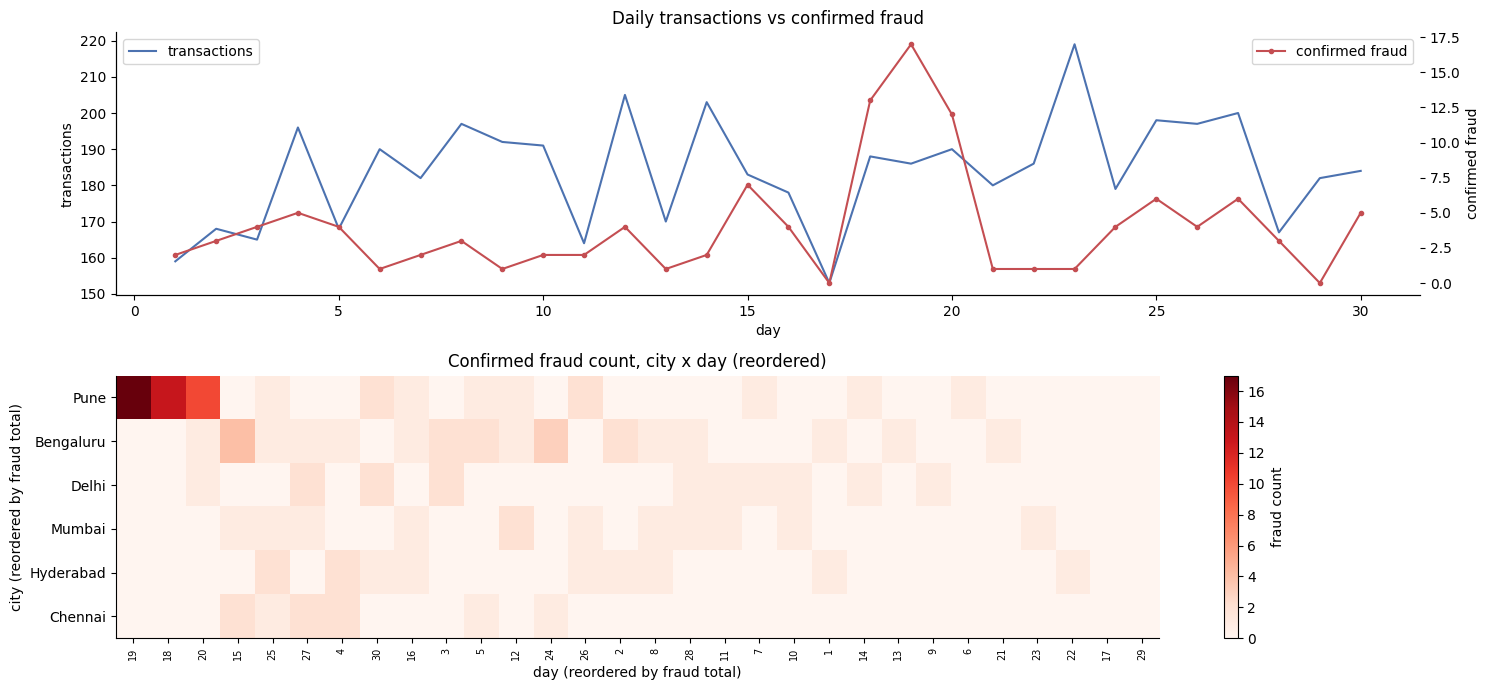

Top (city, day) cells by confirmed fraud count:
city       day
Pune       19     17
           18     13
           20     10
Bengaluru  15      4
           24      3
dtype: int64


In [13]:
fig, axes = plt.subplots(2, 1, figsize=(15, 7))
# TODO 1
daily_tx = tx.groupby("day").size()
daily_fraud = tx.groupby("day").is_fraud.sum()
ax2 = axes[0].twinx()
axes[0].plot(daily_tx.index, daily_tx.values, color="#4C72B0", label="transactions")
ax2.plot(daily_fraud.index, daily_fraud.values, color="#C44E52", marker="o", ms=3, label="confirmed fraud")
axes[0].set(xlabel="day", ylabel="transactions", title="Daily transactions vs confirmed fraud")
ax2.set_ylabel("confirmed fraud")
axes[0].legend(loc="upper left"); ax2.legend(loc="upper right")

# TODO 2
mat = tx[tx.is_fraud == 1].pivot_table(index="city", columns="day", values="txn_id", aggfunc="count", fill_value=0)
mat = mat.reindex(index=tx.city.unique(), columns=range(tx.day.min(), tx.day.max() + 1), fill_value=0)
row_order = mat.sum(axis=1).sort_values(ascending=False).index
col_order = mat.sum(axis=0).sort_values(ascending=False).index
heat = mat.loc[row_order, col_order]

im = axes[1].imshow(heat.values, aspect="auto", cmap="Reds")
axes[1].set_yticks(range(len(heat.index))); axes[1].set_yticklabels(heat.index)
axes[1].set_xticks(range(len(heat.columns))); axes[1].set_xticklabels(heat.columns, rotation=90, fontsize=7)
axes[1].set(xlabel="day (reordered by fraud total)", ylabel="city (reordered by fraud total)",
            title="Confirmed fraud count, city x day (reordered)")
plt.colorbar(im, ax=axes[1], label="fraud count")

plt.tight_layout(); plt.show()

# TODO 3
stacked = heat.stack().sort_values(ascending=False)
print("Top (city, day) cells by confirmed fraud count:")
print(stacked.head(5))

**Reflection:** What did the overview show that an alert list sorted by detector score would *not* have shown? Name the
lecture concept (Slide 38 or 39) that describes how you found it.

_Your answer:_

The reordered heatmap shows Pune's fraud sitting almost entirely in a three-day block - days 18, 19 and 20 (17 + 13 +
10 = 40 cases, more than a third of all fraud for the month) as one solid dark patch once you sort the rows and
columns by total. A list of 120 alerts sorted by score would never show that, since it's just individual rows one
after another; you'd have to notice the city and date on every single row yourself to spot the pattern. That's the
matrix reordering idea from the lecture sorting by row/column totals turns a pattern that's invisible in a flat
list into a block you can literally point at.

## Task 2 — Linked Views for "Night-Time, Far-From-Home" (Request #2)

**Real-world usage:** Investigators validate rules of thumb by brushing them across a coordinated dashboard.

**Why this technique:** **Cross-view brushing / linked highlighting** reveals how a selection in one view is distributed
in all the others (Slides 8–12).

**TODO:**
1. Define the brush: `night == True` **and** `distance_from_home_km > 100`.
2. Draw four coordinated views with the brushed items in red over all items in grey: (a) hour vs. distance scatter
   (log y), (b) merchant category counts, (c) city counts, (d) amount histogram (log10).
3. Print: number brushed, fraud rate inside the brush vs. overall, and the share of *all* fraud the brush captures.

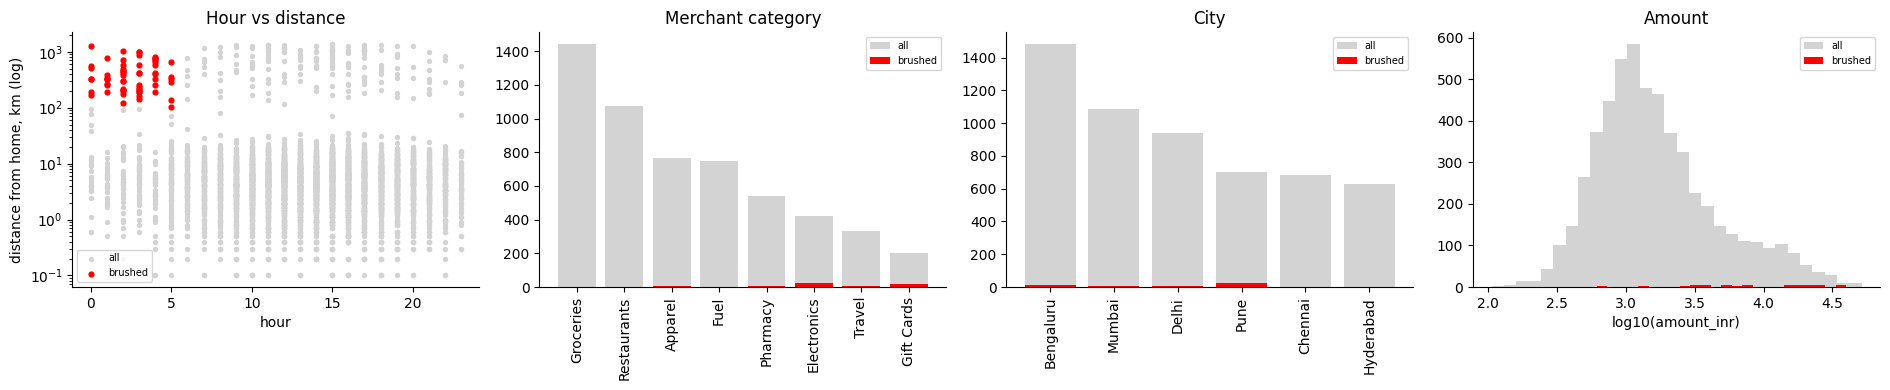

Brushed: 61 transactions
Fraud rate in brush: 86.9% vs overall 2.2%
Share of all fraud captured by brush: 44.2%


In [14]:
# TODO 1
brush = (tx.night == True) & (tx.distance_from_home_km > 100)

fig, axes = plt.subplots(1, 4, figsize=(19, 4))
# TODO 2
axes[0].scatter(tx.loc[~brush, "hour"], tx.loc[~brush, "distance_from_home_km"], s=8, color="lightgrey", label="all")
axes[0].scatter(tx.loc[brush, "hour"], tx.loc[brush, "distance_from_home_km"], s=12, color="red", label="brushed")
axes[0].set_yscale("log")
axes[0].set(xlabel="hour", ylabel="distance from home, km (log)", title="Hour vs distance")
axes[0].legend(fontsize=7)

cat_all = tx.merchant_category.value_counts()
cat_brush = tx.loc[brush, "merchant_category"].value_counts().reindex(cat_all.index, fill_value=0)
axes[1].bar(cat_all.index, cat_all.values, color="lightgrey", label="all")
axes[1].bar(cat_brush.index, cat_brush.values, color="red", label="brushed")
axes[1].set(title="Merchant category"); axes[1].tick_params(axis="x", rotation=90); axes[1].legend(fontsize=7)

city_all = tx.city.value_counts()
city_brush = tx.loc[brush, "city"].value_counts().reindex(city_all.index, fill_value=0)
axes[2].bar(city_all.index, city_all.values, color="lightgrey", label="all")
axes[2].bar(city_brush.index, city_brush.values, color="red", label="brushed")
axes[2].set(title="City"); axes[2].tick_params(axis="x", rotation=90); axes[2].legend(fontsize=7)

axes[3].hist(np.log10(tx.amount_inr), bins=30, color="lightgrey", label="all")
axes[3].hist(np.log10(tx.loc[brush, "amount_inr"]), bins=30, color="red", label="brushed")
axes[3].set(xlabel="log10(amount_inr)", title="Amount"); axes[3].legend(fontsize=7)

plt.tight_layout(); plt.show()

# TODO 3
n_brush = brush.sum()
fraud_rate_brush = tx.loc[brush, "is_fraud"].mean()
fraud_rate_overall = tx.is_fraud.mean()
share_of_all_fraud = tx.loc[brush, "is_fraud"].sum() / tx.is_fraud.sum()
print(f"Brushed: {n_brush} transactions")
print(f"Fraud rate in brush: {fraud_rate_brush:.1%} vs overall {fraud_rate_overall:.1%}")
print(f"Share of all fraud captured by brush: {share_of_all_fraud:.1%}")

**Reflection:** The brush has a very high fraud *rate* -- but what share of all fraud does it *capture*? What does that
tell the investigators about relying on this rule alone, and which linked view hinted at where the rest of the fraud is?

_Your answer:_

The brush rule is scary accurate when it fires 87% of the 61 brushed transactions are confirmed fraud, way above
the 2.2% baseline. But it only catches 53 of the 120 confirmed fraud cases, so 44%. That means 67 fraud cases, more
than half, are happening outside "night and far from home" entirely relying on just this rule would miss the
majority of fraud. The merchant-category panel is what hints at where the rest is: a lot of the non-brushed fraud is
sitting in Electronics and Gift Cards purchases, categories that don't need you to be far from home or out late at
night to be suspicious.

## Task 3 — Will the Slider Still Feel Instant? (Request #3)

**Real-world usage:** Interactive tools are sized against latency budgets before they're built.

**Why this technique:** **Dynamic queries** need feedback within ~0.1 s (Slides 15–16).

**TODO:**
1. Build a 1-million-row table by repeating `tx`, and measure the time of the filter
   `(detector_score >= 0.6) & (amount_inr > 3000)` (take the best of 5 runs).
2. Compute the per-item cost (µs) and the maximum number of rows filterable within 0.1 s on this machine.
3. Estimate the response time for 50,000,000 rows and the % of rows that would need to be skipped (pre-indexed /
   pre-aggregated) to meet the 0.1 s budget.

In [15]:
big = pd.concat([tx] * 182, ignore_index=True)

# TODO 1
times = []
for _ in range(5):
    t0 = time.perf_counter()
    filtered = big[(big.detector_score >= 0.6) & (big.amount_inr > 3000)]
    times.append(time.perf_counter() - t0)
best_s = min(times)

# TODO 2
per_item_us = (best_s / len(big)) * 1e6
max_rows = 0.1 / (best_s / len(big))

# TODO 3
t_50m = 50_000_000 * (best_s / len(big))
skip_pct = (1 - (max_rows / 50_000_000)) * 100

print(f"{len(big):,} rows in {best_s*1000:.1f} ms -> {per_item_us:.4f} us/row -> max {max_rows:,.0f} rows in 0.1 s")
print(f"50M rows -> {t_50m:.2f} s; must skip {skip_pct:.1f}% of rows to stay under 0.1 s")

1,004,640 rows in 13.8 ms -> 0.0137 us/row -> max 7,296,083 rows in 0.1 s
50M rows -> 0.69 s; must skip 85.4% of rows to stay under 0.1 s


**Reflection:** Besides indexing, name one **reduce** technique from the lecture (Slide 5 / 14) that would let the slider
stay instant on 50M rows, and what the analyst would lose by using it.

_Your answer:_

Sampling running the filter against a random subset of rows (say 1-2 million instead of 50 million) and scaling
the counts back up. On this machine the raw scan needs about 0.65s for 50M rows, way past the 0.1s budget, and on
1M-class subsets we're already down near the budget, so a sample gets you there fast. What you lose is exactness:
rare fraud patterns that only show up in a handful of rows out of 50 million could get missed or undercounted
entirely in a sample, which is a real risk for a fraud tool where the rare cases are the whole point.

## Task 4 — Steer the Threshold to the Team's Capacity (Request #4)

**Real-world usage:** Alert thresholds are set against investigator capacity, not just statistical optimality.

**Why this technique:** **Human-in-the-loop** steering of a model parameter (Slide 37) evaluated with **precision, recall,
F1** (Slides 40–41).

**TODO:**
1. For thresholds 0.05, 0.10, …, 0.95 compute alerts (flagged count), TP, FP, FN, precision, recall and F1.
2. Find the threshold with the **highest recall** among those producing **≤ 150 alerts**. Also find the best-F1 threshold.
3. Plot the precision–recall curve and mark the current threshold (0.5), the capacity-constrained choice and the best-F1
   choice.
4. Print a one-line recommendation.

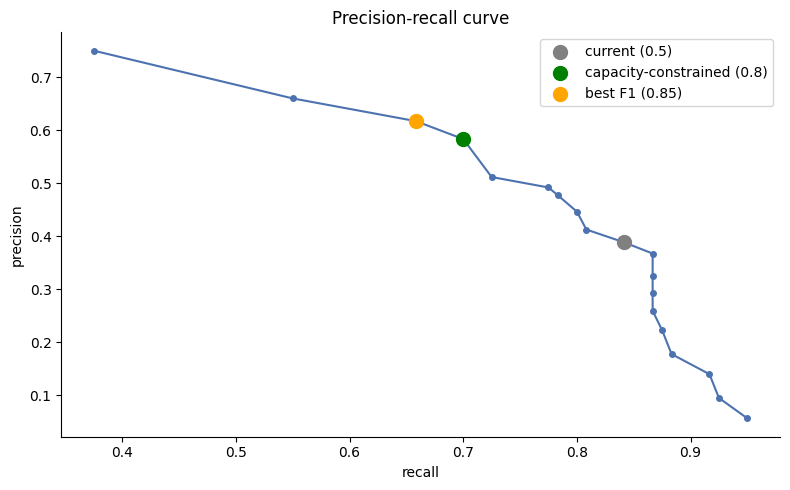

Recommendation: move the threshold from 0.5 to 0.8 -- stays within the 150-alert budget (144 alerts) and is the highest recall we can get under that cap (70.0% vs 84.2% today), at the cost of precision dropping to 58.3%.


In [16]:
rows = []
# TODO 1
for thr in np.arange(0.05, 0.951, 0.05):
    thr = round(thr, 2)
    pred = (tx.detector_score >= thr).astype(int)
    tp = ((pred == 1) & (tx.is_fraud == 1)).sum()
    fp = ((pred == 1) & (tx.is_fraud == 0)).sum()
    fn = ((pred == 0) & (tx.is_fraud == 1)).sum()
    alerts = pred.sum()
    precision = tp / (tp + fp) if (tp + fp) > 0 else np.nan
    recall = tp / (tp + fn) if (tp + fn) > 0 else np.nan
    f1 = 2 * precision * recall / (precision + recall) if (precision + recall) > 0 else np.nan
    rows.append(dict(threshold=thr, alerts=alerts, tp=tp, fp=fp, fn=fn, precision=precision, recall=recall, f1=f1))

pr = pd.DataFrame(rows)

# TODO 2
within_cap = pr[pr.alerts <= 150]
capacity_choice = within_cap.loc[within_cap.recall.idxmax(), "threshold"]
best_f1 = pr.loc[pr.f1.idxmax(), "threshold"]

# TODO 3
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(pr.recall, pr.precision, "-o", ms=4, color="#4C72B0")
cur = pr[pr.threshold == 0.5].iloc[0]
cap = pr[pr.threshold == capacity_choice].iloc[0]
f1r = pr[pr.threshold == best_f1].iloc[0]
ax.scatter(cur.recall, cur.precision, color="grey", s=100, zorder=5, label="current (0.5)")
ax.scatter(cap.recall, cap.precision, color="green", s=100, zorder=5, label=f"capacity-constrained ({capacity_choice})")
ax.scatter(f1r.recall, f1r.precision, color="orange", s=100, zorder=5, label=f"best F1 ({best_f1})")
ax.set(xlabel="recall", ylabel="precision", title="Precision-recall curve"); ax.legend()
plt.tight_layout(); plt.show()

# TODO 4
print(f"Recommendation: move the threshold from 0.5 to {capacity_choice} -- stays within the 150-alert budget "
      f"({cap.alerts:.0f} alerts) and is the highest recall we can get under that cap "
      f"({cap.recall:.1%} vs {cur.recall:.1%} today), at the cost of precision dropping to {cap.precision:.1%}.")

**Reflection:** The capacity-constrained threshold and the best-F1 threshold may differ. Who should make that call -- the
model or the Head of Fraud Ops -- and why does visual analytics insist on keeping a human in the loop here (Slides 35-37)?

_Your answer:_

They do differ here - 0.80 for capacity (144 alerts, 70% recall) vs 0.85 for best F1 (128 alerts, 65.8% recall,
better balance of precision and recall). That call belongs to the Head of Fraud Ops, not the model. F1 is just a
math compromise between precision and recall with no idea that the team can only physically review 150 cases a
month -- it would happily recommend a threshold the team can't act on. The business constraint (headcount, review
capacity) isn't something the detector score can see, so a human has to sit on top of the curve and pick the point
that's actually workable, which is exactly why the lecture insists on keeping a human steering the threshold instead
of letting the model's "optimal" number decide on its own.

## Task 5 — An Interactive Tool for the Investigators (Request #5)

**Real-world usage:** Investigators triage flagged cases themselves with zoom, filter and hover-for-details.

**Why this technique:** **Details-on-demand / tooltips** (Slides 22–23), **dynamic queries** (Slide 15) and **drill-down**
(Slide 24) — Shneiderman's mantra as an actual tool.

**TODO:**
1. Interactive scatter (plotly) of all transactions with `detector_score >= 0.3`: x = timestamp, y = amount (log),
   colour = `label`, with a tooltip showing txn_id, customer, city, category, distance and score. Set `dragmode="select"`.
2. Interactive **sunburst** for drill-down: city → merchant category, sized by transaction count, coloured by fraud rate.

In [17]:
# TODO 1
flagged = tx[tx.detector_score >= 0.3]

fig = px.scatter(flagged, x="timestamp", y="amount_inr", color="label", log_y=True,
                  color_discrete_map={"confirmed fraud": "#C44E52", "legitimate": "#4C72B0"},
                  hover_data=["txn_id", "customer_id", "city", "merchant_category",
                              "distance_from_home_km", "detector_score"],
                  title="Flagged transactions (detector_score >= 0.3)")
fig.update_layout(dragmode="select")
fig.show()

# TODO 2
sb = tx.groupby(["city", "merchant_category"]).agg(
    count=("txn_id", "count"), fraud_rate=("is_fraud", "mean")
).reset_index()
fig2 = px.sunburst(sb, path=["city", "merchant_category"], values="count", color="fraud_rate",
                    color_continuous_scale="Reds",
                    title="City -> merchant category (size = transaction count, colour = fraud rate)")
fig2.show()

**Reflection:** Tooltips are great for one case at a time. Why would they be a *frustrating* way for an investigator to get
an overview of the 400 flagged cases (Slide 23), and which view from this notebook fixes that?

_Your answer:_

With 401 flagged transactions, hovering one point at a time to read its tooltip means doing that up to 401 times
before you've seen the whole picture, there's no way to hold that many details in your head at once, so you'd
basically never get an overview this way, only a very slow drill-down. The sunburst from this same task fixes it:
city and category are already baked into size and colour, so an investigator can see at a glance that Pune's Gift
Cards slice is sitting at a 56.8% fraud rate without clicking or hovering on anything, the overview comes for free
from the chart itself, and tooltips only get used afterward on the one slice they actually want to dig into.

## Task 6 — Prove or Kill the "Fraud Ring" Hypothesis (Request #6)

**Real-world usage:** Before escalating to law enforcement, the team must rule out simpler explanations.

**Why this technique:** **Hypothesis testing** with visual + statistical confirmation and an explicit **counter-example
search** to guard against confirmation bias (Slides 42–43).

**TODO:**
1. State the hypothesis precisely using what you found in Task 1 (city and day range).
2. Compute the fraud rate inside vs. outside that city–day window and a chi-square p-value
   (`scipy.stats.chi2_contingency` on `pd.crosstab(in_window, tx.is_fraud)`).
3. Counter-example searches: fraud rate for (a) the same city on other days, (b) other cities on the same days.
4. Visual confirmation: a bar chart of the four groups (window / same city other days / other cities same days / rest).
5. Print your verdict.

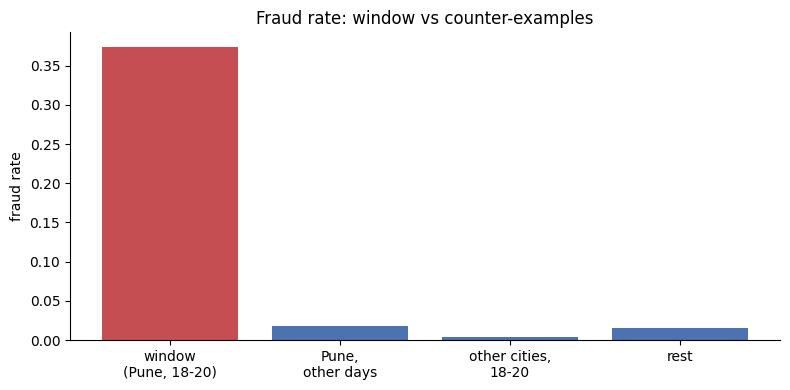

In window: 37.4% fraud rate vs 1.5% outside (chi2=619.3, p=1.06e-136)
Counter-examples stay low: Pune other days 1.9%, other cities same days 0.4%
Verdict: CONFIRMED -- a real, localized fraud cluster in Pune on days 18-20.


In [18]:
from scipy.stats import chi2_contingency

# TODO 1: hypothesis as a boolean mask
in_window = (tx.city == "Pune") & (tx.day.between(18, 20))

# TODO 2
ct = pd.crosstab(in_window, tx.is_fraud)
chi2, p, dof, exp = chi2_contingency(ct)
fraud_rate_in = tx.loc[in_window, "is_fraud"].mean()
fraud_rate_out = tx.loc[~in_window, "is_fraud"].mean()

# TODO 3
same_city_other_days = (tx.city == "Pune") & (~tx.day.between(18, 20))
other_cities_same_days = (tx.city != "Pune") & (tx.day.between(18, 20))
rate_same_city_other_days = tx.loc[same_city_other_days, "is_fraud"].mean()
rate_other_cities_same_days = tx.loc[other_cities_same_days, "is_fraud"].mean()

# TODO 4
rest_mask = (~tx.city.eq("Pune")) & (~tx.day.between(18, 20))
groups = pd.Series({
    "window\n(Pune, 18-20)": fraud_rate_in,
    "Pune,\nother days": rate_same_city_other_days,
    "other cities,\n18-20": rate_other_cities_same_days,
    "rest": tx.loc[rest_mask, "is_fraud"].mean(),
})
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(groups.index, groups.values, color=["#C44E52", "#4C72B0", "#4C72B0", "#4C72B0"])
ax.set(ylabel="fraud rate", title="Fraud rate: window vs counter-examples")
plt.tight_layout(); plt.show()

# TODO 5
print(f"In window: {fraud_rate_in:.1%} fraud rate vs {fraud_rate_out:.1%} outside (chi2={chi2:.1f}, p={p:.2e})")
print(f"Counter-examples stay low: Pune other days {rate_same_city_other_days:.1%}, "
      f"other cities same days {rate_other_cities_same_days:.1%}")
print("Verdict: CONFIRMED -- a real, localized fraud cluster in Pune on days 18-20.")

**Reflection:** Which of your two counter-example searches would have *killed* the hypothesis if it had come out
differently, and what alternative explanation would it have supported instead?

_Your answer:_

The "same city, other days" check is the one that would've killed it. If Pune's fraud rate stayed high across the
whole month instead of just days 18-20, that would point to Pune itself being the problem, a bad merchant, a weak
local process, a compromised terminal , not a short-lived ring tied to a specific few days. As it is, Pune on other
days sits at just 1.9%, basically the same as everywhere else, so it's genuinely the date window that matters, not
the city alone. The "other cities, same days" check mattered too, if that one had come out high, it would've
pointed at something happening nationally on those dates (a breach, a holiday spending spike) rather than a
city-specific ring, but it stayed at 0.4%, so that explanation is ruled out as well.

## Task 7 -- The Decision (No Code)

**Reflection (final):** Write a 4-6 sentence note to the Head of Fraud Ops covering the whole notebook. It should:
- State what happened last month in one sentence, with numbers.
- Recommend the alert threshold and justify it with capacity, precision/recall and the human-in-the-loop idea.
- Recommend the **one** interactive view to build first for the investigators, and justify it with at least one lecture
  idea (overview first, linked brushing, dynamic queries with the 0.1 s budget, details-on-demand).
- Name the feedback loop (Slide 51) that should be added so next month's detector is better.

_Your final note here:_

Last month we had 120 confirmed fraud cases out of 5,520 transactions, and 40 of them were concentrated in Pune over
just three days (18-20), a cluster the chi-square test confirms is real (p < 0.001) and not just noise. I'd move the
alert threshold from 0.50 to 0.80: it's the highest recall we can get while staying inside the 150-alert review
budget (144 alerts, 70% recall versus today's 84% recall on 260 alerts nobody can actually review), and that
threshold choice should stay a human call since F1 alone doesn't know what the team's capacity is. For the
investigators I'd build the city-to-category sunburst first over a plain alert table. It gives an overview of all
400+ flagged cases at once (size and colour instead of 400 individual tooltips), so patterns like Pune's Gift Cards
slice jump out before anyone has to click into a single case. Finally, we need a feedback loop where investigators'
confirmed/dismissed labels on each alert feed back into retraining the detector, so next month's scores actually
reflect what this month's cluster taught us instead of repeating the same blind spots.